In [1]:
%pip install torch torchvision matplotlib numpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
import matplotlib.pyplot as plt
import torch.nn as nn
import torch.optim as optim



In [3]:
# Tekrarlanabilirlik
torch.manual_seed(42)

# Görüntü dönüşümü
transform = transforms.ToTensor()

# Eğitim verilerini yükleme
full_train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

# Test verilerini yükleme
test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 9.91M/9.91M [00:24<00:00, 401kB/s]


Extracting ./data\MNIST\raw\train-images-idx3-ubyte.gz to ./data\MNIST\raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 28.9k/28.9k [00:00<00:00, 166kB/s]


Extracting ./data\MNIST\raw\train-labels-idx1-ubyte.gz to ./data\MNIST\raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 1.65M/1.65M [00:03<00:00, 477kB/s]


Extracting ./data\MNIST\raw\t10k-images-idx3-ubyte.gz to ./data\MNIST\raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 4.54k/4.54k [00:00<?, ?B/s]

Extracting ./data\MNIST\raw\t10k-labels-idx1-ubyte.gz to ./data\MNIST\raw



In [4]:
train_dataset, val_dataset = random_split(
    full_train_dataset,
    [54000, 6000],
    generator=torch.Generator().manual_seed(42)
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Train: 54000
Validation: 6000
Test: 10000


In [5]:
batch_size = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

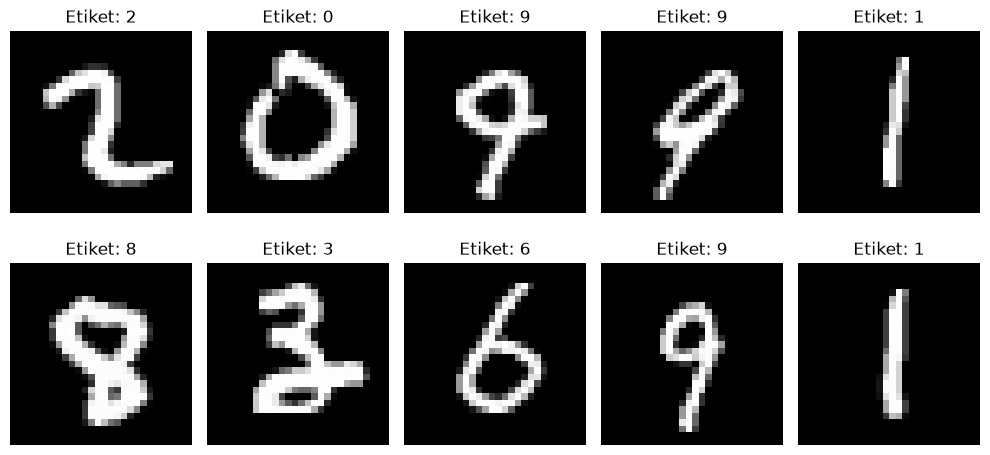

In [6]:
images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(f"Etiket: {labels[i].item()}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [7]:
print("Görüntü batch boyutu:", images.shape)
print("Etiket batch boyutu:", labels.shape)

print("Minimum piksel:", images.min().item())
print("Maksimum piksel:", images.max().item())

Görüntü batch boyutu: torch.Size([32, 1, 28, 28])
Etiket batch boyutu: torch.Size([32])
Minimum piksel: 0.0
Maksimum piksel: 1.0


In [9]:
class MLP(nn.Module):
    def __init__(self):
        super(MLP, self).__init__()

        self.flatten = nn.Flatten()

        self.fc1 = nn.Linear(784, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 10)

        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.flatten(x)

        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))

        x = self.fc3(x)

        return x

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Kullanılan cihaz:", device)

model = MLP().to(device)

print(model)

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

epochs = 20

images, labels = next(iter(train_loader))

images = images.to(device)

with torch.no_grad():
    outputs = model(images)

print("Giriş boyutu:", images.shape)
print("Çıkış boyutu:", outputs.shape)

total_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Toplam öğrenilebilir parametre:", total_params)

Kullanılan cihaz: cuda
MLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=64, bias=True)
  (fc3): Linear(in_features=64, out_features=10, bias=True)
  (relu): ReLU()
)
Giriş boyutu: torch.Size([32, 1, 28, 28])
Çıkış boyutu: torch.Size([32, 10])
Toplam öğrenilebilir parametre: 109386


In [10]:
import time

# Sonuçların kaydedileceği listeler
train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

# En iyi modelin takibi
best_val_loss = float("inf")
best_epoch = 0

# Eğitim süresini başlat
start_time = time.perf_counter()

for epoch in range(epochs):

    # =========================
    # TRAINING
    # =========================

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Gradyanları sıfırla
        optimizer.zero_grad()

        # Forward propagation
        outputs = model(images)

        # Loss hesaplama
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Ağırlıkları güncelle
        optimizer.step()

        # Loss değerlerini biriktir
        running_loss += loss.item() * images.size(0)

        # Tahmin edilen sınıflar
        predictions = torch.argmax(outputs, dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_accuracy = 100 * correct / total

    # =========================
    # VALIDATION
    # =========================

    model.eval()

    running_val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_val_loss += loss.item() * images.size(0)

            predictions = torch.argmax(outputs, dim=1)

            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss = running_val_loss / val_total
    val_accuracy = 100 * val_correct / val_total

    # =========================
    # SONUÇLARI KAYDET
    # =========================

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)

    print(
        f"Epoch [{epoch+1}/{epochs}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Acc: %{train_accuracy:.2f} | "
        f"Val Acc: %{val_accuracy:.2f}"
    )

    # En iyi modeli kaydet
    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_epoch = epoch + 1

        torch.save(model.state_dict(), "best_mlp.pth")

# GPU işlemlerinin tamamlanmasını bekle
if device.type == "cuda":
    torch.cuda.synchronize()

# Toplam eğitim süresi
training_time = time.perf_counter() - start_time

print("\nEğitim tamamlandı!")
print(f"Toplam eğitim süresi: {training_time:.2f} saniye")
print(f"En iyi epoch: {best_epoch}")
print(f"En düşük validation loss: {best_val_loss:.4f}")

Epoch [1/20] | Train Loss: 0.2917 | Val Loss: 0.1688 | Train Acc: %91.70 | Val Acc: %95.05
Epoch [2/20] | Train Loss: 0.1217 | Val Loss: 0.1227 | Train Acc: %96.31 | Val Acc: %96.35
Epoch [3/20] | Train Loss: 0.0822 | Val Loss: 0.1180 | Train Acc: %97.44 | Val Acc: %96.62
Epoch [4/20] | Train Loss: 0.0627 | Val Loss: 0.0824 | Train Acc: %98.04 | Val Acc: %97.60
Epoch [5/20] | Train Loss: 0.0482 | Val Loss: 0.0853 | Train Acc: %98.41 | Val Acc: %97.50
Epoch [6/20] | Train Loss: 0.0386 | Val Loss: 0.0823 | Train Acc: %98.77 | Val Acc: %97.63
Epoch [7/20] | Train Loss: 0.0317 | Val Loss: 0.0950 | Train Acc: %98.98 | Val Acc: %97.27
Epoch [8/20] | Train Loss: 0.0288 | Val Loss: 0.1008 | Train Acc: %99.03 | Val Acc: %97.15
Epoch [9/20] | Train Loss: 0.0238 | Val Loss: 0.0846 | Train Acc: %99.26 | Val Acc: %97.72
Epoch [10/20] | Train Loss: 0.0213 | Val Loss: 0.1091 | Train Acc: %99.27 | Val Acc: %97.47
Epoch [11/20] | Train Loss: 0.0165 | Val Loss: 0.1053 | Train Acc: %99.42 | Val Acc: %97.

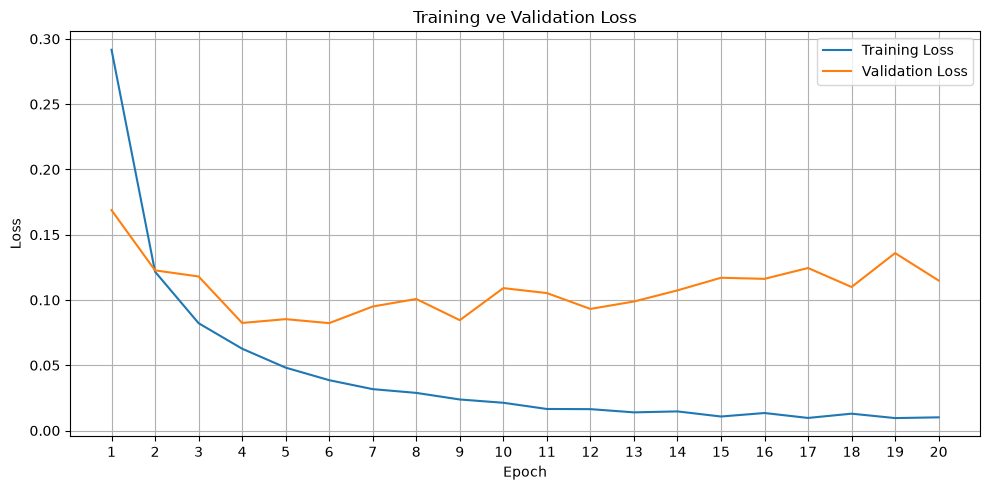

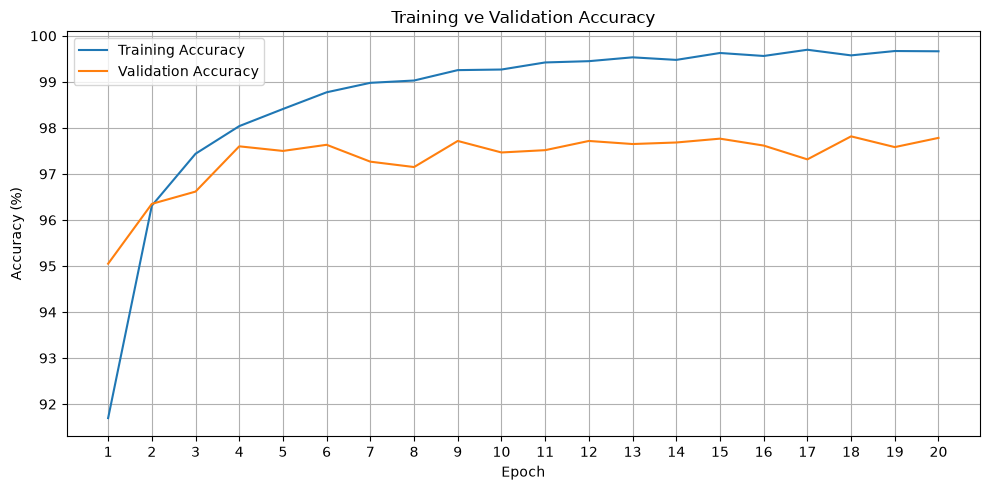

In [11]:
plt.figure(figsize=(10, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training ve Validation Loss")

plt.xticks(range(0, epochs), range(1, epochs + 1))
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig("loss_graph.png", dpi=300)
plt.show()

plt.figure(figsize=(10, 5))

plt.plot(train_accuracies, label="Training Accuracy")
plt.plot(val_accuracies, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training ve Validation Accuracy")

plt.xticks(range(0, epochs), range(1, epochs + 1))
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig("accuracy_graph.png", dpi=300)
plt.show()

In [12]:
# En iyi modeli yükle
model.load_state_dict(
    torch.load(
        "best_mlp.pth",
        map_location=device,
        weights_only=True
    )
)

model.eval()

test_correct = 0
test_total = 0
test_loss_sum = 0.0

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        loss = criterion(outputs, labels)
        test_loss_sum += loss.item() * images.size(0)

        predictions = torch.argmax(outputs, dim=1)

        test_correct += (predictions == labels).sum().item()
        test_total += labels.size(0)

test_accuracy = 100 * test_correct / test_total
test_loss = test_loss_sum / test_total

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: %{test_accuracy:.2f}")
print(f"Doğru Tahmin: {test_correct}/{test_total}")

Test Loss: 0.0726
Test Accuracy: %97.82
Doğru Tahmin: 9782/10000
